# Exploring ERA5 2m temperature with xarray

## 1. Opening the data

In [ ]:
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

path = "gs://weatherbench2/datasets/era5/1959-2022-6h-64x32_equiangular_with_poles_conservative.zarr"
ds = xr.open_zarr(path, storage_options={"token": "anon"})
ds

<xarray.Dataset> Size: 81GB
Dimensions:                                           (time: 92040,
                                                       longitude: 64,
                                                       latitude: 32, level: 13)
Coordinates:
  * time                                              (time) datetime64[ns] 736kB ...
  * longitude                                         (longitude) float64 512B ...
  * latitude                                          (latitude) float64 256B ...
  * level                                             (level) int64 104B 50 ....
Data variables: (12/38)
    10m_u_component_of_wind                           (time, longitude, latitude) float32 754MB ...
    10m_v_component_of_wind                           (time, longitude, latitude) float32 754MB ...
    10m_wind_speed                                    (time, longitude, latitude) float32 754MB ...
    2m_temperature                                    (time, longitude, latitude) float32 754MB ...
    angle_of_sub_gridscale_orography                  (longitude, latitude) float32 8kB ...
    anisotropy_of_sub_gridscale_orography             (longitude, latitude) float32 8kB ...
    ...                                                ...
    type_of_high_vegetation                           (longitude, latitude) float32 8kB ...
    type_of_low_vegetation                            (longitude, latitude) float32 8kB ...
    u_component_of_wind                               (time, level, longitude, latitude) float32 10GB ...
    v_component_of_wind                               (time, level, longitude, latitude) float32 10GB ...
    vertical_velocity                                 (time, level, longitude, latitude) float32 10GB ...
    wind_speed                                        (time, level, longitude, latitude) float32 10GB ...

## 2. A global snapshot: 1 July 2020, 12:00 UTC

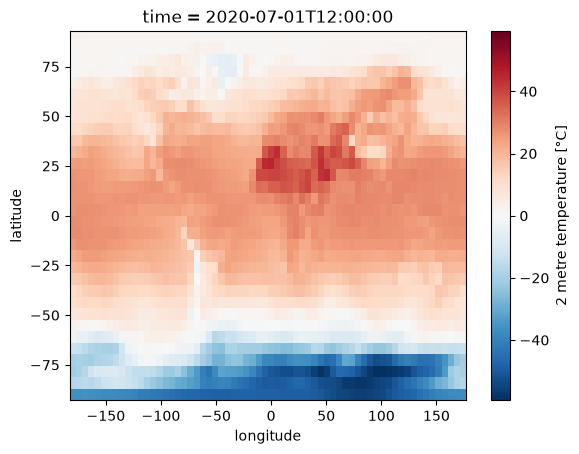

In [23]:
t2m_july = ds['2m_temperature'].sel(time='2020-07-01T12:00')
t2m_july = t2m_july - 273.15
t2m_july.attrs['units'] = '°C'
t2m_july = t2m_july.assign_coords(longitude=((t2m_july['longitude'] + 180)%360)-180).sortby("longitude")
t2m_july.plot(x="longitude", y="latitude")

## 3. Time series: Darmstadt and Reading

In [31]:
#the 5.625° grid cell containing Darmstadt
darmstadt = ds["2m_temperature"].sel(latitude=49.9, longitude=8.65, method="nearest")

#the 5.625° grid cell containing Reading
reading = ds["2m_temperature"].sel(latitude=51.4, longitude=360-0.97, method="nearest")

In [ ]:
def resampled_mean_celsius(series, start, end, time_frame):
    """Mean 2 m temperature in °C over regular time bins, between start and end."""
    series = series.sel(time=slice(start, end))
    series = series - 273.15
    series = series.resample(time=time_frame).mean()
    series.attrs['units'] = '°C'
    return series

reading_daily = resampled_mean_celsius(reading, "2020-01-01", "2020-12-31", "1D")
darmstadt_daily = resampled_mean_celsius(darmstadt, "2020-01-01", "2020-12-31", "1D")

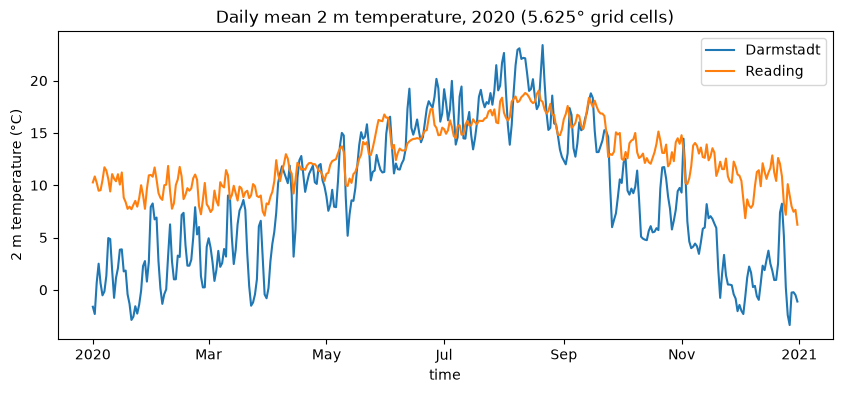

In [33]:
fig, ax = plt.subplots(figsize=(10, 4))     # one figure, one axes

darmstadt_daily.plot(ax=ax, label="Darmstadt")   # draw on that axes
reading_daily.plot(ax=ax, label="Reading")       # same axes, so same plot

ax.set_ylabel("2 m temperature (°C)")
ax.set_title("Daily mean 2 m temperature, 2020 (5.625° grid cells)")
ax.legend()

In [37]:
darmstadt_monthly = resampled_mean_celsius(darmstadt, "2020-01-01", "2020-12-31", "1MS")
reading_monthly = resampled_mean_celsius(reading, "2020-01-01", "2020-12-31", "1MS")

darmstadt_amplitude = float(darmstadt_monthly.max() - darmstadt_monthly.min())
reading_amplitude = float(reading_monthly.max() - reading_monthly.min())

print(f"Seasonal amplitude 2020 (warmest minus coldest month):")
print(f"Seasonal amplitude, Darmstadt: {float(darmstadt_amplitude):.1f} °C")
print(f"Seasonal amplitude, Reading: {float(reading_amplitude):.1f} °C")

Seasonal amplitude 2020 (warmest minus coldest month):
Seasonal amplitude, Darmstadt: 17.6 °C
Seasonal amplitude, Reading: 8.3 °C
